<a href="https://colab.research.google.com/github/hasby-umutoniwabo/ML_technique_I-Summative/blob/main/notebook/hausa_sentiment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!nvidia-smi

Wed Oct 14 07:09:51 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   50C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
!pip install -q datasets transformers evaluate gradio
print("done")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 1.8 MB/s eta 0:00:00
done


Imports and a fixed random seed

In [3]:
import os, random, re
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

# Fixing the seed means we get the same numbers every time we rerun.
# Without this, our experiment comparisons would be meaningless.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Running on:", device)

Running on: cuda


Load the Dataset

In [4]:
!git clone -q https://github.com/afrisenti-semeval/afrisent-semeval-2023.git
!find afrisent-semeval-2023 -name "*hau*" | head -20

afrisent-semeval-2023/sentiment_lexicon/ha/hausa_negative.csv
afrisent-semeval-2023/sentiment_lexicon/ha/hausa_positive.csv
afrisent-semeval-2023/data_with_annotators_labels/hausa_individual_labels.csv
afrisent-semeval-2023/data/hau


Inspecting

In [5]:
import glob

# List every file and peek at its first 3 lines so we know the separator and the column names before we try to load anything.
for f in sorted(glob.glob("afrisent-semeval-2023/data/hau/*")):
    print("FILE:", f)
    with open(f, encoding="utf-8") as fh:
        for i, line in enumerate(fh):
            print("   ", line.rstrip()[:120])
            if i >= 2:
                break
    print()

FILE: afrisent-semeval-2023/data/hau/dev.tsv
    tweet	label
    @user @user Allah ya kai rahmarsa kabarin ta 🤲🤲🤲😭😭 Uwa ga gimbiyar👑👑👑 Alhanislam Hauwa Maina	positive
    @user 🤣🤣🤣 wannan kasa tamu Allah ya kyauta wai lailai sai an maida talaka baisan me yake ba Allah ya kyauta.	positive

FILE: afrisent-semeval-2023/data/hau/test.tsv
    tweet	label
    ah su rahama za axha madara sa lemu fah mudai deja mn muna tchikin sa alhmdllh allah ya karbi ibadumu yakuma yafe mana k
    tohh allah shi taimaka	positive

FILE: afrisent-semeval-2023/data/hau/train.tsv
    tweet	label
    @user Da kudin da Arewa babu wani abin azo agani da yayi wa alummah allah ya isa yacucemu wlh yarikitamana kasa yarikita
    @user Kaga wani Adu ar Banda💔😭 wai a haka Shi ne shugaban sojoji.... Gaskiya Buhari kaci Amanan mu da kasa wannan mutum 



Load the splits

In [6]:
import pandas as pd

base = "afrisent-semeval-2023/data/hau"

# Files are tab separated with a tweet + label header. Straightforward.
train_df = pd.read_csv(f"{base}/train.tsv", sep="\t", encoding="utf-8")
val_df   = pd.read_csv(f"{base}/dev.tsv",   sep="\t", encoding="utf-8")
test_df  = pd.read_csv(f"{base}/test.tsv",  sep="\t", encoding="utf-8")

print("train:", train_df.shape)
print("dev  :", val_df.shape)
print("test :", test_df.shape)
print("columns:", list(train_df.columns))
train_df.head()

train: (14172, 2)
dev  : (2677, 2)
test : (5303, 2)
columns: ['tweet', 'label']


,tweet,label
0,@user Da kudin da Arewa babu wani abin azo aga...,negative
1,@user Kaga wani Adu ar Banda💔😭 wai a haka Shi ...,negative
2,@user Sai haquri fa yan madrid daman kunce cha...,negative
3,@user Hmmm yanzu kai kasan girman allah daxaka...,negative
4,@user @user Wai gwamno nin Nigeria suna afa kw...,negative


In [7]:
expected = {"positive", "negative", "neutral"}

for name, df in [("train", train_df), ("dev", val_df), ("test", test_df)]:
    found = set(df["label"].dropna().unique())
    bad = found - expected
    nulls = df.isna().sum().sum()
    print(f"{name}: {len(df):,} rows | labels={found} | junk={bad} | nulls={nulls}")

train: 14,172 rows | labels={'positive', 'neutral', 'negative'} | junk=set() | nulls=0
dev: 2,677 rows | labels={'positive', 'neutral', 'negative'} | junk=set() | nulls=0
test: 5,303 rows | labels={'positive', 'neutral', 'negative'} | junk=set() | nulls=0


Label distribution

label
neutral     4912
positive    4687
negative    4573
Name: count, dtype: int64

label
neutral     34.7
positive    33.1
negative    32.3
Name: proportion, dtype: float64


<Axes: title={'center': 'Hausa training labels'}, xlabel='label'>

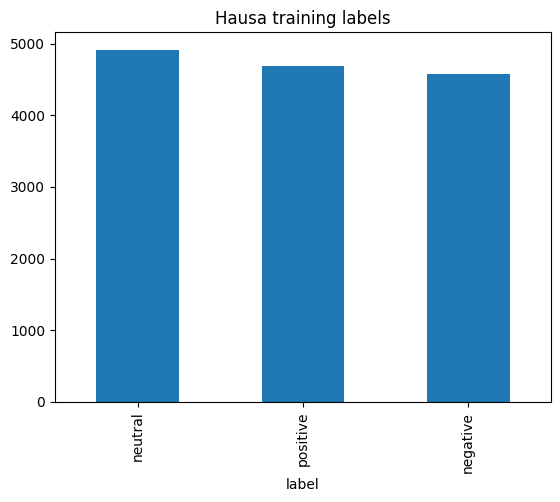

In [8]:
print(train_df["label"].value_counts())
print()
print((train_df["label"].value_counts(normalize=True) * 100).round(1))

train_df["label"].value_counts().plot(kind="bar", title="Hausa training labels")

One real example per class

In [9]:
# Seeing actual tweets per class helps a lot when we get to error analysis.
for lab in ["positive", "negative", "neutral"]:
    sub = train_df[train_df["label"] == lab]
    print(f"===== {lab.upper()} ({len(sub):,} tweets) =====")
    for t in sub["tweet"].head(2):
        print("  ", str(t)[:150])
    print()

===== POSITIVE (4,687 tweets) =====
   @user Innalillahi wa'ina ilaihim raji'u 😭😭😭😭 Ya Allah kana ganin halin da muke ciki Ya Allah kawo mana dauki Amma wllh Allah shugaban nin kasar mu hak
   @user @user @user 🔥🔥har gobe ruwa na maganin dauda gaskia umar sarki ne

===== NEGATIVE (4,573 tweets) =====
   @user Da kudin da Arewa babu wani abin azo agani da yayi wa alummah allah ya isa yacucemu wlh yarikitamana kasa yarikitamana kasuwanci harkar ilimi ha
   @user Kaga wani Adu ar Banda💔😭 wai a haka Shi ne shugaban sojoji.... Gaskiya Buhari kaci Amanan mu da kasa wannan mutum ah wajen nan

===== NEUTRAL (4,912 tweets) =====
   @user Waye minlitan ilimi kuma? 🤔🤔
   @user Aradu ya dauki kashedi🤣



Cleaning function

In [10]:
import re

def clean_tweet(text):
    text = str(text)
    text = re.sub(r"http\S+|www\.\S+", "", text)   # drop links
    text = re.sub(r"@\w+", "@user", text)          # normalise handles
    text = re.sub(r"\s+", " ", text)               # newlines + double spaces
    return text.strip()

# Emojis stay. In tweets they carry real sentiment and removing them throws away signal
print(clean_tweet("Ina kwana @abdul123 ka duba https://t.co/xyz   😊😊"))

Ina kwana @user ka duba 😊😊


Apply it

In [11]:
for df in (train_df, val_df, test_df):
    df["clean"] = df["tweet"].apply(clean_tweet)

train_df["n_words"] = train_df["clean"].str.split().str.len()
print(train_df["n_words"].describe().round(1))
print("95th percentile:", train_df["n_words"].quantile(0.95))

train_df[["tweet", "clean"]].head(3)

count    14172.0
mean        14.0
std          9.6
min          4.0
25%          7.0
50%         11.0
75%         17.0
max         58.0
Name: n_words, dtype: float64
95th percentile: 35.0


,tweet,clean
0,@user Da kudin da Arewa babu wani abin azo aga...,@user Da kudin da Arewa babu wani abin azo aga...
1,@user Kaga wani Adu ar Banda💔😭 wai a haka Shi ...,@user Kaga wani Adu ar Banda💔😭 wai a haka Shi ...
2,@user Sai haquri fa yan madrid daman kunce cha...,@user Sai haquri fa yan madrid daman kunce cha...


Labels to numbers

In [12]:
# Models need integers, not strings. we keep both maps so we can translate back to words when we look at predictions.
LABELS = ["negative", "neutral", "positive"]
label2id = {l: i for i, l in enumerate(LABELS)}
id2label = {i: l for l, i in label2id.items()}

for df in (train_df, val_df, test_df):
    df["y"] = df["label"].map(label2id)

print(label2id)
print(train_df[["label", "y"]].drop_duplicates().sort_values("y"))

{'negative': 0, 'neutral': 1, 'positive': 2}
         label  y
0     negative  0
4573   neutral  1
9485  positive  2


Results tracker

In [13]:
# Every experiment appends one row here. This table becomes
# Table 1 in the report, so we fill it as we go rather than
# scrambling to reconstruct it at the end.
results = []

def log_result(name, split, acc, f1_macro, f1_weighted, notes=""):
    results.append({
        "model": name, "split": split,
        "accuracy": round(acc, 4),
        "f1_macro": round(f1_macro, 4),
        "f1_weighted": round(f1_weighted, 4),
        "notes": notes,
    })
    print(f"{name} [{split}] -> acc {acc:.4f} | macroF1 {f1_macro:.4f}")

def show_results():
    return pd.DataFrame(results)

Shared evaluation function

In [14]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

def evaluate(y_true, y_pred, name, split, notes=""):
    acc = accuracy_score(y_true, y_pred)
    fm  = f1_score(y_true, y_pred, average="macro")
    fw  = f1_score(y_true, y_pred, average="weighted")
    log_result(name, split, acc, fm, fw, notes)
    print()
    print(classification_report(y_true, y_pred, target_names=LABELS, digits=3))
    return acc, fm, fw

Baseline 0: the lexicon rule

In [15]:
# Dead simple rule: count positive vs negative words from the
# human-built Hausa lexicon that ships with the dataset.
# No learning at all - this is our absolute floor.
pos_words = set(pd.read_csv("afrisent-semeval-2023/sentiment_lexicon/ha/hausa_positive.csv",
                            header=None)[0].astype(str).str.lower())
neg_words = set(pd.read_csv("afrisent-semeval-2023/sentiment_lexicon/ha/hausa_negative.csv",
                            header=None)[0].astype(str).str.lower())
print(f"lexicon: {len(pos_words)} positive, {len(neg_words)} negative words")

def lexicon_predict(text):
    toks = re.findall(r"\w+", text.lower())
    score = sum(t in pos_words for t in toks) - sum(t in neg_words for t in toks)
    if score > 0: return label2id["positive"]
    if score < 0: return label2id["negative"]
    return label2id["neutral"]

lex_pred = val_df["clean"].apply(lexicon_predict)
evaluate(val_df["y"], lex_pred, "Lexicon rule", "dev", "no learning")

lexicon: 1215 positive, 1001 negative words
Lexicon rule [dev] -> acc 0.5622 | macroF1 0.5577

              precision    recall  f1-score   support

    negative      0.729     0.397     0.514       894
     neutral      0.493     0.619     0.549       896
    positive      0.559     0.671     0.610       887

    accuracy                          0.562      2677
   macro avg      0.594     0.562     0.558      2677
weighted avg      0.594     0.562     0.558      2677



(0.5621964886066493, 0.5576614677455667, 0.5575192770140871)

Baseline 1: TF-IDF features

In [16]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Word ngrams catch phrases. Char ngrams catch spelling variants,
# which matters a lot here since Hausa tweets aren't spelled consistently.
vec = TfidfVectorizer(
    analyzer="char_wb", ngram_range=(2, 5),
    min_df=2, max_features=50000, sublinear_tf=True,
)

Xtr = vec.fit_transform(train_df["clean"])   # fit on TRAIN ONLY
Xva = vec.transform(val_df["clean"])
Xte = vec.transform(test_df["clean"])

print("feature matrix:", Xtr.shape)

feature matrix: (14172, 50000)


Train logistic regression

In [17]:
from sklearn.linear_model import LogisticRegression

clf = LogisticRegression(max_iter=2000, C=1.0, n_jobs=-1)
clf.fit(Xtr, train_df["y"])

evaluate(val_df["y"], clf.predict(Xva), "TF-IDF + LogReg", "dev", "char 2-5grams")

TF-IDF + LogReg [dev] -> acc 0.7691 | macroF1 0.7705

              precision    recall  f1-score   support

    negative      0.762     0.694     0.726       894
     neutral      0.686     0.792     0.735       896
    positive      0.880     0.822     0.850       887

    accuracy                          0.769      2677
   macro avg      0.776     0.769     0.771      2677
weighted avg      0.776     0.769     0.770      2677



(0.769144564811356, 0.7705037877410632, 0.7702692860897671)

Confusion matrix

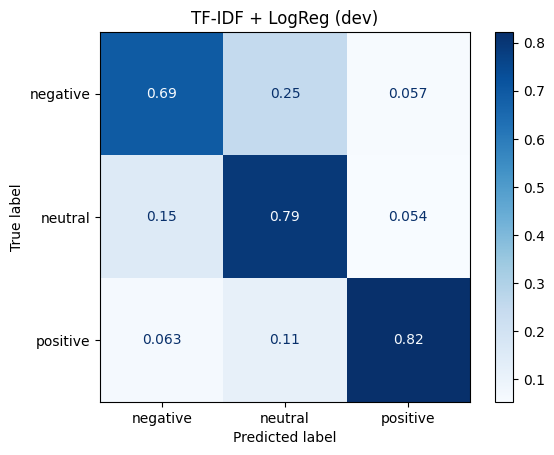

,model,split,accuracy,f1_macro,f1_weighted,notes
0,Lexicon rule,dev,0.5622,0.5577,0.5575,no learning
1,TF-IDF + LogReg,dev,0.7691,0.7705,0.7703,char 2-5grams


In [18]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    val_df["y"], clf.predict(Xva),
    display_labels=LABELS, cmap="Blues", normalize="true"
)
plt.title("TF-IDF + LogReg (dev)")
plt.show()

show_results()

Checkpoint after the baseline


In [4]:
import os

SAVE = "/content/drive/MyDrive/hausa_nlp"
try:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=True)
except Exception as e:
    print("Drive mount failed, using local storage:", e)
    SAVE = "/content/hausa_nlp"

os.makedirs(SAVE, exist_ok=True)
print("SAVE =", SAVE)
print("model files:", os.listdir(f"{SAVE}/final_model"))

Mounted at /content/drive
SAVE = /content/drive/MyDrive/hausa_nlp
model files: ['config.json', 'model.safetensors', 'tokenizer_config.json', 'tokenizer.json']


Saving

In [21]:
from google.colab import drive
drive.mount('/content/drive')

import os
SAVE = "/content/drive/MyDrive/hausa_nlp"
os.makedirs(SAVE, exist_ok=True)
print("saving to:", SAVE)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
saving to: /content/drive/MyDrive/hausa_nlp


Vocabulary

In [22]:
from collections import Counter

# Keep words seen at least twice. Rare words can't be learned from 14k tweets and just bloat the embedding table.
MIN_FREQ = 2

counter = Counter()
for t in train_df["clean"]:
    counter.update(t.lower().split())

vocab = ["<pad>", "<unk>"] + [w for w, c in counter.items() if c >= MIN_FREQ]
word2idx = {w: i for i, w in enumerate(vocab)}

print(f"total unique words: {len(counter):,}")
print(f"vocab kept:         {len(vocab):,}")
print(f"dropped as rare:    {len(counter) - len(vocab) + 2:,}")

total unique words: 34,359
vocab kept:         9,514
dropped as rare:    24,847


Encode to padded sequence

In [23]:
MAX_LEN = 40   # 95th percentile was 35 words, so 40 covers nearly everything

def encode(text):
    ids = [word2idx.get(w, 1) for w in text.lower().split()][:MAX_LEN]
    ids += [0] * (MAX_LEN - len(ids))        # 0 = <pad>
    return ids

Xtr_seq = np.array([encode(t) for t in train_df["clean"]])
Xva_seq = np.array([encode(t) for t in val_df["clean"]])
Xte_seq = np.array([encode(t) for t in test_df["clean"]])

print(Xtr_seq.shape)
print("example:", Xtr_seq[0][:15])

(14172, 40)
example: [ 2  3  4  3  5  6  7  8  9 10  3 11 12 13 14]


Dataloaders

In [24]:
from torch.utils.data import TensorDataset, DataLoader

def make_loader(X, y, shuffle):
    ds = TensorDataset(torch.tensor(X, dtype=torch.long),
                       torch.tensor(np.array(y), dtype=torch.long))
    return DataLoader(ds, batch_size=64, shuffle=shuffle)

train_loader = make_loader(Xtr_seq, train_df["y"], True)
val_loader   = make_loader(Xva_seq, val_df["y"],   False)
test_loader  = make_loader(Xte_seq, test_df["y"],  False)

print("batches per epoch:", len(train_loader))

batches per epoch: 222


The model

In [25]:
import torch.nn as nn

class BiLSTMClassifier(nn.Module):
    def __init__(self, vocab_size, emb_dim=200, hidden=128, n_classes=3, dropout=0.4):
        super().__init__()
        # padding_idx=0 keeps pad tokens as zeros that never learn
        self.emb  = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        self.lstm = nn.LSTM(emb_dim, hidden, batch_first=True,
                            bidirectional=True, num_layers=1)
        self.drop = nn.Dropout(dropout)
        self.fc   = nn.Linear(hidden * 2, n_classes)   # *2 for both directions

    def forward(self, x):
        e = self.emb(x)                 # (batch, len, emb)
        out, _ = self.lstm(e)           # (batch, len, hidden*2)
        pooled = out.max(dim=1).values  # strongest signal anywhere in the tweet
        return self.fc(self.drop(pooled))

model = BiLSTMClassifier(len(vocab)).to(device)
print(model)
print("trainable params:", sum(p.numel() for p in model.parameters() if p.requires_grad))

BiLSTMClassifier(
  (emb): Embedding(9514, 200, padding_idx=0)
  (lstm): LSTM(200, 128, batch_first=True, bidirectional=True)
  (drop): Dropout(p=0.4, inplace=False)
  (fc): Linear(in_features=256, out_features=3, bias=True)
)
trainable params: 2241491


Train

In [26]:
import torch.optim as optim

def run_epoch(model, loader, optimizer=None):
    train_mode = optimizer is not None
    model.train() if train_mode else model.eval()
    crit = nn.CrossEntropyLoss()
    total, preds, golds = 0.0, [], []

    with torch.set_grad_enabled(train_mode):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss = crit(logits, yb)
            if train_mode:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total += loss.item() * len(yb)
            preds += logits.argmax(1).cpu().tolist()
            golds += yb.cpu().tolist()

    return total / len(golds), np.array(golds), np.array(preds)


EPOCHS = 8
model = BiLSTMClassifier(len(vocab)).to(device)
opt = optim.Adam(model.parameters(), lr=1e-3)

best_f1, best_state = 0, None
for ep in range(1, EPOCHS + 1):
    tr_loss, _, _ = run_epoch(model, train_loader, opt)
    va_loss, g, p = run_epoch(model, val_loader)
    f1 = f1_score(g, p, average="macro")
    flag = ""
    if f1 > best_f1:                        # keep only the best epoch
        best_f1 = f1
        best_state = {k: v.clone() for k, v in model.state_dict().items()}
        flag = "  <-- best"
    print(f"epoch {ep}: train_loss {tr_loss:.4f} | val_loss {va_loss:.4f} | val_macroF1 {f1:.4f}{flag}")

model.load_state_dict(best_state)
print(f"\nrestored best epoch, macroF1 {best_f1:.4f}")

epoch 1: train_loss 0.8641 | val_loss 0.7329 | val_macroF1 0.6714  <-- best
epoch 2: train_loss 0.6736 | val_loss 0.6560 | val_macroF1 0.7156  <-- best
epoch 3: train_loss 0.5401 | val_loss 0.6406 | val_macroF1 0.7226  <-- best
epoch 4: train_loss 0.4224 | val_loss 0.6733 | val_macroF1 0.7251  <-- best
epoch 5: train_loss 0.3206 | val_loss 0.7084 | val_macroF1 0.7209
epoch 6: train_loss 0.2379 | val_loss 0.8265 | val_macroF1 0.7075
epoch 7: train_loss 0.1663 | val_loss 0.9033 | val_macroF1 0.7252  <-- best
epoch 8: train_loss 0.1612 | val_loss 0.9506 | val_macroF1 0.7173

restored best epoch, macroF1 0.7252


Score and checkpoint

In [27]:
_, g, p = run_epoch(model, val_loader)
evaluate(g, p, "BiLSTM (random emb)", "dev", f"emb200 hid128 maxlen{MAX_LEN}")

torch.save(model.state_dict(), f"{SAVE}/bilstm.pt")
show_results().to_csv(f"{SAVE}/results.csv", index=False)
show_results()

BiLSTM (random emb) [dev] -> acc 0.7243 | macroF1 0.7252

              precision    recall  f1-score   support

    negative      0.704     0.652     0.677       894
     neutral      0.650     0.715     0.681       896
    positive      0.829     0.806     0.817       887

    accuracy                          0.724      2677
   macro avg      0.728     0.725     0.725      2677
weighted avg      0.727     0.724     0.725      2677



,model,split,accuracy,f1_macro,f1_weighted,notes
0,Lexicon rule,dev,0.5622,0.5577,0.5575,no learning
1,TF-IDF + LogReg,dev,0.7691,0.7705,0.7703,char 2-5grams
2,BiLSTM (random emb),dev,0.7243,0.7252,0.7249,emb200 hid128 maxlen40


**PART 4 — Fine-tune AfroXLM-R**

Tokenizer

In [28]:
from transformers import AutoTokenizer

MODEL_NAME = "Davlan/afro-xlmr-base"   # XLM-R adapted to African languages
tok = AutoTokenizer.from_pretrained(MODEL_NAME)

# See how it splits Hausa - subwords mean no <unk> problem
s = train_df["clean"].iloc[0]
print(s[:100])
print()
print(tok.tokenize(s)[:25])

config.json:   0%|          | 0.00/707 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/398 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/9.08M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

@user Da kudin da Arewa babu wani abin azo agani da yayi wa alummah allah ya isa yacucemu wlh yariki

['▁@', 'user', '▁Da', '▁ku', 'din', '▁da', '▁Arewa', '▁babu', '▁wani', '▁abin', '▁az', 'o', '▁a', 'gani', '▁da', '▁yayi', '▁wa', '▁al', 'um', 'mah', '▁', 'allah', '▁ya', '▁isa', '▁ya']


Tokenize all splits

In [29]:
MAX_LEN_TF = 64   # subwords > words, so more room than the BiLSTM's 40

def tokenize_df(df):
    enc = tok(list(df["clean"]), truncation=True, padding="max_length",
              max_length=MAX_LEN_TF, return_tensors="pt")
    return enc["input_ids"], enc["attention_mask"], torch.tensor(df["y"].values)

tr_ids, tr_mask, tr_y = tokenize_df(train_df)
va_ids, va_mask, va_y = tokenize_df(val_df)
te_ids, te_mask, te_y = tokenize_df(test_df)

print(tr_ids.shape, tr_mask.shape, tr_y.shape)

torch.Size([14172, 64]) torch.Size([14172, 64]) torch.Size([14172])


Dataloaders

In [30]:
BATCH = 16   # 32 may OOM on a T4 with this model

def make_tf_loader(ids, mask, y, shuffle):
    return DataLoader(TensorDataset(ids, mask, y), batch_size=BATCH, shuffle=shuffle)

tf_train = make_tf_loader(tr_ids, tr_mask, tr_y, True)
tf_val   = make_tf_loader(va_ids, va_mask, va_y, False)
tf_test  = make_tf_loader(te_ids, te_mask, te_y, False)

print("batches per epoch:", len(tf_train))

batches per epoch: 886


Load the model

In [31]:
from transformers import AutoModelForSequenceClassification

def fresh_model():
    # Downloads pretrained weights, then bolts a new 3-class head on top.
    # The warning about uninitialised weights is expected - that's our head.
    return AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=3, id2label=id2label, label2id=label2id
    ).to(device)

tf_model = fresh_model()
print("params:", sum(p.numel() for p in tf_model.parameters())/1e6, "M")

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: Davlan/afro-xlmr-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
classifier.out_proj.bias   | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


params: 278.045955 M


Training loop

In [32]:
from transformers import get_linear_schedule_with_warmup

def run_tf_epoch(model, loader, optimizer=None, scheduler=None, scaler=None):
    train_mode = optimizer is not None
    model.train() if train_mode else model.eval()
    total, preds, golds = 0.0, [], []

    with torch.set_grad_enabled(train_mode):
        for ids, mask, yb in loader:
            ids, mask, yb = ids.to(device), mask.to(device), yb.to(device)
            # fp16 - roughly 2x faster on a T4
            with torch.amp.autocast("cuda"):
                out = model(input_ids=ids, attention_mask=mask, labels=yb)
            if train_mode:
                optimizer.zero_grad()
                scaler.scale(out.loss).backward()
                scaler.step(optimizer); scaler.update(); scheduler.step()
            total += out.loss.item() * len(yb)
            preds += out.logits.argmax(1).cpu().tolist()
            golds += yb.cpu().tolist()

    return total / len(golds), np.array(golds), np.array(preds)


def train_transformer(lr=2e-5, epochs=3, tag="AfroXLM-R"):
    model = fresh_model()
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    steps = len(tf_train) * epochs
    sched = get_linear_schedule_with_warmup(opt, int(0.1 * steps), steps)
    scaler = torch.amp.GradScaler("cuda")

    best_f1, best_state = 0, None
    for ep in range(1, epochs + 1):
        trl, _, _ = run_tf_epoch(model, tf_train, opt, sched, scaler)
        val, g, p = run_tf_epoch(model, tf_val)
        f1 = f1_score(g, p, average="macro")
        flag = ""
        if f1 > best_f1:
            best_f1 = f1
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            flag = "  <-- best"
        print(f"[{tag}] epoch {ep}: train_loss {trl:.4f} | val_loss {val:.4f} | val_macroF1 {f1:.4f}{flag}")

    model.load_state_dict(best_state)
    return model, best_f1

tf_model, best = train_transformer(lr=2e-5, epochs=3, tag="AfroXLM-R lr2e-5")

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: Davlan/afro-xlmr-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
classifier.out_proj.bias   | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[AfroXLM-R lr2e-5] epoch 1: train_loss 0.7519 | val_loss 0.5957 | val_macroF1 0.7478  <-- best
[AfroXLM-R lr2e-5] epoch 2: train_loss 0.5331 | val_loss 0.5586 | val_macroF1 0.7733  <-- best
[AfroXLM-R lr2e-5] epoch 3: train_loss 0.4356 | val_loss 0.5321 | val_macroF1 0.7878  <-- best


Score it

AfroXLM-R base [dev] -> acc 0.7878 | macroF1 0.7878

              precision    recall  f1-score   support

    negative      0.797     0.696     0.743       894
     neutral      0.711     0.798     0.752       896
    positive      0.866     0.870     0.868       887

    accuracy                          0.788      2677
   macro avg      0.792     0.788     0.788      2677
weighted avg      0.791     0.788     0.788      2677



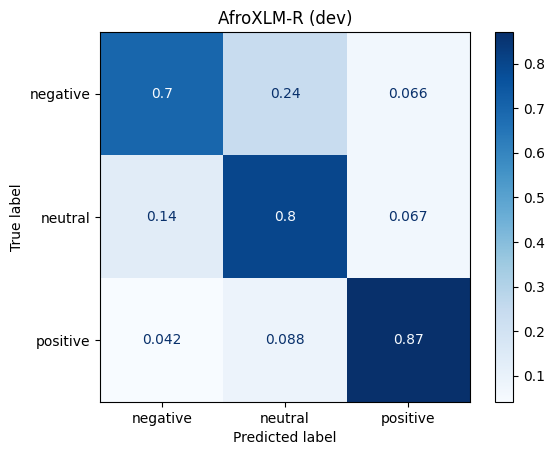

,model,split,accuracy,f1_macro,f1_weighted,notes
0,Lexicon rule,dev,0.5622,0.5577,0.5575,no learning
1,TF-IDF + LogReg,dev,0.7691,0.7705,0.7703,char 2-5grams
2,BiLSTM (random emb),dev,0.7243,0.7252,0.7249,emb200 hid128 maxlen40
3,AfroXLM-R base,dev,0.7878,0.7878,0.7875,lr2e-5 bs16 3ep maxlen64


In [33]:
_, g, p = run_tf_epoch(tf_model, tf_val)
evaluate(g, p, "AfroXLM-R base", "dev", f"lr2e-5 bs{BATCH} 3ep maxlen{MAX_LEN_TF}")

ConfusionMatrixDisplay.from_predictions(g, p, display_labels=LABELS,
                                        cmap="Blues", normalize="true")
plt.title("AfroXLM-R (dev)")
plt.show()

show_results()

**PART 5: Experiments**

Memory helper

In [34]:
import gc

# 278M params eats VRAM. Clear between runs or the second one OOMs.
def free_gpu():
    gc.collect()
    torch.cuda.empty_cache()
    print(f"GPU in use: {torch.cuda.memory_allocated()/1e9:.2f} GB")

free_gpu()

GPU in use: 2.29 GB


Experiment 1: train longer

In [35]:
# Val loss was still dropping at epoch 3, so the model hadn't converged.
# Same settings, more epochs.
del tf_model; free_gpu()

exp1_model, _ = train_transformer(lr=2e-5, epochs=5, tag="E1 lr2e-5 5ep")

_, g, p = run_tf_epoch(exp1_model, tf_val)
evaluate(g, p, "AfroXLM-R", "dev", "lr2e-5 bs16 5ep")

GPU in use: 0.06 GB


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: Davlan/afro-xlmr-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
classifier.out_proj.bias   | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[E1 lr2e-5 5ep] epoch 1: train_loss 0.7616 | val_loss 0.6047 | val_macroF1 0.7448  <-- best
[E1 lr2e-5 5ep] epoch 2: train_loss 0.5370 | val_loss 0.5123 | val_macroF1 0.7913  <-- best
[E1 lr2e-5 5ep] epoch 3: train_loss 0.4182 | val_loss 0.5325 | val_macroF1 0.8036  <-- best
[E1 lr2e-5 5ep] epoch 4: train_loss 0.3209 | val_loss 0.5729 | val_macroF1 0.7929
[E1 lr2e-5 5ep] epoch 5: train_loss 0.2521 | val_loss 0.6186 | val_macroF1 0.8014
AfroXLM-R [dev] -> acc 0.8028 | macroF1 0.8036

              precision    recall  f1-score   support

    negative      0.794     0.754     0.773       894
     neutral      0.737     0.796     0.765       896
    positive      0.885     0.859     0.872       887

    accuracy                          0.803      2677
   macro avg      0.805     0.803     0.804      2677
weighted avg      0.805     0.803     0.803      2677



(0.8027642883825178, 0.8035549589622479, 0.8033478854336588)

Experiment 2: higher learning rate

In [36]:
# Does a bigger step size converge faster, or overshoot and destabilise?
del exp1_model; free_gpu()

exp2_model, _ = train_transformer(lr=3e-5, epochs=5, tag="E2 lr3e-5 5ep")

_, g, p = run_tf_epoch(exp2_model, tf_val)
evaluate(g, p, "AfroXLM-R", "dev", "lr3e-5 bs16 5ep")

show_results().to_csv(f"{SAVE}/results.csv", index=False)
show_results()

GPU in use: 0.06 GB


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: Davlan/afro-xlmr-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
classifier.out_proj.bias   | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[E2 lr3e-5 5ep] epoch 1: train_loss 0.7666 | val_loss 0.5477 | val_macroF1 0.7783  <-- best
[E2 lr3e-5 5ep] epoch 2: train_loss 0.5270 | val_loss 0.5191 | val_macroF1 0.7889  <-- best
[E2 lr3e-5 5ep] epoch 3: train_loss 0.4001 | val_loss 0.5916 | val_macroF1 0.7848
[E2 lr3e-5 5ep] epoch 4: train_loss 0.2873 | val_loss 0.5835 | val_macroF1 0.7970  <-- best
[E2 lr3e-5 5ep] epoch 5: train_loss 0.1991 | val_loss 0.6882 | val_macroF1 0.7904
AfroXLM-R [dev] -> acc 0.7972 | macroF1 0.7970

              precision    recall  f1-score   support

    negative      0.815     0.724     0.767       894
     neutral      0.728     0.787     0.756       896
    positive      0.856     0.882     0.868       887

    accuracy                          0.797      2677
   macro avg      0.799     0.797     0.797      2677
weighted avg      0.799     0.797     0.797      2677



,model,split,accuracy,f1_macro,f1_weighted,notes
0,Lexicon rule,dev,0.5622,0.5577,0.5575,no learning
1,TF-IDF + LogReg,dev,0.7691,0.7705,0.7703,char 2-5grams
2,BiLSTM (random emb),dev,0.7243,0.7252,0.7249,emb200 hid128 maxlen40
3,AfroXLM-R base,dev,0.7878,0.7878,0.7875,lr2e-5 bs16 3ep maxlen64
4,AfroXLM-R,dev,0.8028,0.8036,0.8033,lr2e-5 bs16 5ep
5,AfroXLM-R,dev,0.7972,0.7970,0.7968,lr3e-5 bs16 5ep


Experiment 3: do emojis actually matter

In [37]:
# We chose to KEEP emojis during cleaning. This tests whether that
# choice was right - strip them, retrain, compare.
import re

EMOJI = re.compile("[\U0001F000-\U0001FAFF\u2600-\u27BF\uFE0F\u2069\u2066]+")

def strip_emoji(t):
    return re.sub(r"\s+", " ", EMOJI.sub(" ", t)).strip()

noem_train = train_df["clean"].apply(strip_emoji)
noem_val   = val_df["clean"].apply(strip_emoji)

print("WITH :", train_df['clean'].iloc[1][:90])
print("WITHOUT:", noem_train.iloc[1][:90])

def tok_texts(texts, y):
    enc = tok(list(texts), truncation=True, padding="max_length",
              max_length=MAX_LEN_TF, return_tensors="pt")
    return TensorDataset(enc["input_ids"], enc["attention_mask"],
                         torch.tensor(y.values))

tf_train_noem = DataLoader(tok_texts(noem_train, train_df["y"]), batch_size=BATCH, shuffle=True)
tf_val_noem   = DataLoader(tok_texts(noem_val,   val_df["y"]),   batch_size=BATCH, shuffle=False)

WITH : @user Kaga wani Adu ar Banda💔😭 wai a haka Shi ne shugaban sojoji.... Gaskiya Buhari kaci A
WITHOUT: @user Kaga wani Adu ar Banda wai a haka Shi ne shugaban sojoji.... Gaskiya Buhari kaci Ama


Run the ablation

In [38]:
del exp2_model; free_gpu()

# Point the trainer at the emoji-free loaders
tf_train_backup, tf_val_backup = tf_train, tf_val
tf_train, tf_val = tf_train_noem, tf_val_noem

exp3_model, _ = train_transformer(lr=2e-5, epochs=5, tag="E3 no-emoji")
_, g, p = run_tf_epoch(exp3_model, tf_val)
evaluate(g, p, "AfroXLM-R", "dev", "lr2e-5 5ep, emojis REMOVED")

# restore
tf_train, tf_val = tf_train_backup, tf_val_backup
show_results().to_csv(f"{SAVE}/results.csv", index=False)
show_results()

GPU in use: 0.06 GB


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: Davlan/afro-xlmr-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
classifier.out_proj.bias   | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[E3 no-emoji] epoch 1: train_loss 0.7863 | val_loss 0.5876 | val_macroF1 0.7621  <-- best
[E3 no-emoji] epoch 2: train_loss 0.5443 | val_loss 0.5393 | val_macroF1 0.7818  <-- best
[E3 no-emoji] epoch 3: train_loss 0.4265 | val_loss 0.5516 | val_macroF1 0.7887  <-- best
[E3 no-emoji] epoch 4: train_loss 0.3322 | val_loss 0.5620 | val_macroF1 0.7988  <-- best
[E3 no-emoji] epoch 5: train_loss 0.2644 | val_loss 0.6164 | val_macroF1 0.7939
AfroXLM-R [dev] -> acc 0.7987 | macroF1 0.7988

              precision    recall  f1-score   support

    negative      0.795     0.751     0.772       894
     neutral      0.747     0.781     0.764       896
    positive      0.856     0.865     0.860       887

    accuracy                          0.799      2677
   macro avg      0.799     0.799     0.799      2677
weighted avg      0.799     0.799     0.799      2677



,model,split,accuracy,f1_macro,f1_weighted,notes
0,Lexicon rule,dev,0.5622,0.5577,0.5575,no learning
1,TF-IDF + LogReg,dev,0.7691,0.7705,0.7703,char 2-5grams
2,BiLSTM (random emb),dev,0.7243,0.7252,0.7249,emb200 hid128 maxlen40
3,AfroXLM-R base,dev,0.7878,0.7878,0.7875,lr2e-5 bs16 3ep maxlen64
4,AfroXLM-R,dev,0.8028,0.8036,0.8033,lr2e-5 bs16 5ep
5,AfroXLM-R,dev,0.7972,0.7970,0.7968,lr3e-5 bs16 5ep
6,AfroXLM-R,dev,0.7987,0.7988,0.7986,"lr2e-5 5ep, emojis REMOVED"


**PART 6  Final model + test scores**

Retrain the winner and save it immediately

In [39]:
del exp3_model; free_gpu()

# Reseting the seed first so this run is reproducible.
torch.manual_seed(SEED); np.random.seed(SEED); random.seed(SEED)

final_model, _ = train_transformer(lr=2e-5, epochs=5, tag="FINAL")
#saving
final_model.save_pretrained(f"{SAVE}/final_model")
tok.save_pretrained(f"{SAVE}/final_model")
print("saved to", f"{SAVE}/final_model")

GPU in use: 0.06 GB


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: Davlan/afro-xlmr-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
classifier.out_proj.bias   | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[FINAL] epoch 1: train_loss 0.7422 | val_loss 0.5636 | val_macroF1 0.7660  <-- best
[FINAL] epoch 2: train_loss 0.5324 | val_loss 0.5157 | val_macroF1 0.7917  <-- best
[FINAL] epoch 3: train_loss 0.4183 | val_loss 0.5509 | val_macroF1 0.7832
[FINAL] epoch 4: train_loss 0.3308 | val_loss 0.5704 | val_macroF1 0.7961  <-- best
[FINAL] epoch 5: train_loss 0.2645 | val_loss 0.6154 | val_macroF1 0.7943


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

saved to /content/drive/MyDrive/hausa_nlp/final_model


Test set. One shot only

In [40]:
# First and only time we touch test. Everything until now was tuned on dev.
_, g_test, p_test = run_tf_epoch(final_model, tf_test)
evaluate(g_test, p_test, "AfroXLM-R FINAL", "TEST", "lr2e-5 bs16 5ep")

# Baselines on test too, so the comparison is fair
evaluate(test_df["y"], clf.predict(Xte), "TF-IDF + LogReg", "TEST", "char 2-5grams")
evaluate(test_df["y"], test_df["clean"].apply(lexicon_predict), "Lexicon rule", "TEST", "no learning")

show_results().to_csv(f"{SAVE}/results.csv", index=False)
show_results()

AfroXLM-R FINAL [TEST] -> acc 0.7788 | macroF1 0.7787

              precision    recall  f1-score   support

    negative      0.731     0.794     0.762      1759
     neutral      0.757     0.695     0.725      1789
    positive      0.851     0.848     0.850      1755

    accuracy                          0.779      5303
   macro avg      0.780     0.779     0.779      5303
weighted avg      0.780     0.779     0.778      5303

TF-IDF + LogReg [TEST] -> acc 0.7466 | macroF1 0.7453

              precision    recall  f1-score   support

    negative      0.656     0.814     0.727      1759
     neutral      0.768     0.598     0.672      1789
    positive      0.844     0.830     0.837      1755

    accuracy                          0.747      5303
   macro avg      0.756     0.747     0.745      5303
weighted avg      0.756     0.747     0.745      5303

Lexicon rule [TEST] -> acc 0.5497 | macroF1 0.5452

              precision    recall  f1-score   support

    negative      0.7

,model,split,accuracy,f1_macro,f1_weighted,notes
0,Lexicon rule,dev,0.5622,0.5577,0.5575,no learning
1,TF-IDF + LogReg,dev,0.7691,0.7705,0.7703,char 2-5grams
2,BiLSTM (random emb),dev,0.7243,0.7252,0.7249,emb200 hid128 maxlen40
3,AfroXLM-R base,dev,0.7878,0.7878,0.7875,lr2e-5 bs16 3ep maxlen64
4,AfroXLM-R,dev,0.8028,0.8036,0.8033,lr2e-5 bs16 5ep
5,AfroXLM-R,dev,0.7972,0.7970,0.7968,lr3e-5 bs16 5ep
6,AfroXLM-R,dev,0.7987,0.7988,0.7986,"lr2e-5 5ep, emojis REMOVED"
7,AfroXLM-R FINAL,TEST,0.7788,0.7787,0.7783,lr2e-5 bs16 5ep
8,TF-IDF + LogReg,TEST,0.7466,0.7453,0.7448,char 2-5grams
9,Lexicon rule,TEST,0.5497,0.5452,0.5451,no learning


Test confusion matrix

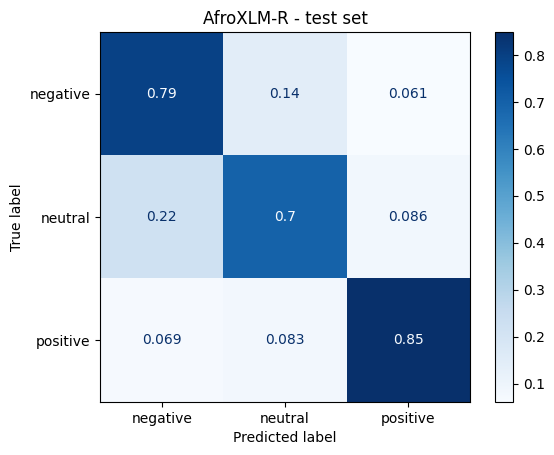

In [41]:
ConfusionMatrixDisplay.from_predictions(g_test, p_test, display_labels=LABELS,
                                        cmap="Blues", normalize="true")
plt.title("AfroXLM-R - test set")
plt.savefig(f"{SAVE}/confusion_test.png", dpi=150, bbox_inches="tight")
plt.show()

Build an error table

In [42]:
err_df = test_df.copy()
err_df["pred"] = [id2label[i] for i in p_test]
err_df["correct"] = err_df["label"] == err_df["pred"]

print(f"wrong: {(~err_df['correct']).sum():,} of {len(err_df):,}")
print()
# Which confusions dominate?
print(err_df[~err_df["correct"]].groupby(["label", "pred"]).size()
      .sort_values(ascending=False))

wrong: 1,173 of 5,303

label     pred    
neutral   negative    392
negative  neutral     254
neutral   positive    153
positive  neutral     145
          negative    121
negative  positive    108
dtype: int64


Read the actual failures

In [43]:
# The point is to find PATTERNS, not just count errors.
pd.set_option("display.max_colwidth", 160)

for true_lab, pred_lab in [("negative","neutral"), ("neutral","negative"), ("positive","neutral")]:
    sub = err_df[(err_df["label"]==true_lab) & (err_df["pred"]==pred_lab)]
    print(f"\n########## true={true_lab} -> predicted={pred_lab}  ({len(sub)} cases)")
    for t in sub["clean"].head(5):
        print("  •", t[:170])


########## true=negative -> predicted=neutral  (254 cases)
  • bbc idan bakuda abin posting ku saka mana hoton buhari mu zazzageshi mana
  • adam mayen mata aure xaka kara
  • da iyaye zasu gane cewar yin makarantar boko a najeriya scam ce da sun daina kai yaran su
  • tab kashiga uku king
  • kamar dole ne auren

########## true=neutral -> predicted=negative  (392 cases)
  • too ashe sunada bambanci uhumm
  • ina ruwan kaleee
  • mu gwauraye bamusan dadi ba ko
  • gaskiya day mumaday indan niger itma ta kwshe yan kasarta daga côte divoire
  • you get tuwon towo

########## true=positive -> predicted=neutral  (145 cases)
  • my governor where are you muma fah munaso
  • buqatan maji haji sallah
  • lolz duk inda ta kwana sha ne thts very right
  • rahama yan mata
  • daidai kenan muna bayan pantami me naira da dollars


Does length predict failure?

           accuracy     n
bucket                   
(0, 5]        0.804  1235
(5, 10]       0.762  1872
(10, 20]      0.757  1299
(20, 40]      0.799   752
(40, 100]     0.876   145


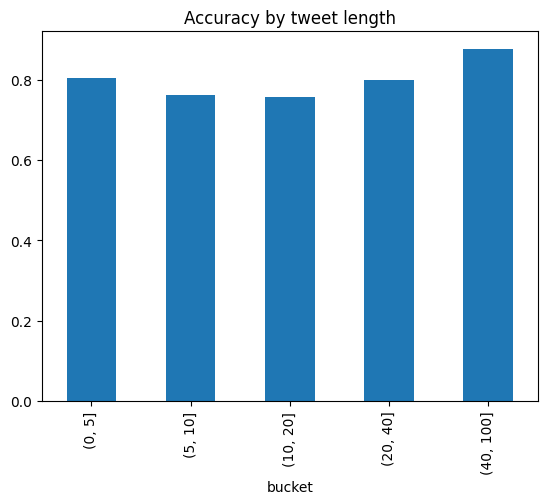

In [44]:
err_df["n_words"] = err_df["clean"].str.split().str.len()
err_df["bucket"] = pd.cut(err_df["n_words"], [0,5,10,20,40,100])

acc_by_len = err_df.groupby("bucket", observed=True)["correct"].agg(["mean","size"])
acc_by_len.columns = ["accuracy", "n"]
print(acc_by_len.round(3))

acc_by_len["accuracy"].plot(kind="bar", title="Accuracy by tweet length")
plt.show()

Confidence on errors

In [45]:
import torch.nn.functional as F

# Is the model confidently wrong, or just unsure?
probs = []
final_model.eval()
with torch.no_grad():
    for ids, mask, _ in tf_test:
        out = final_model(input_ids=ids.to(device), attention_mask=mask.to(device))
        probs.append(F.softmax(out.logits, dim=1).cpu())
probs = torch.cat(probs).numpy()

err_df["confidence"] = probs.max(axis=1)
print(err_df.groupby("correct")["confidence"].describe().round(3))

err_df.to_csv(f"{SAVE}/error_analysis.csv", index=False)

          count   mean    std    min    25%    50%    75%    max
correct                                                         
False    1173.0  0.774  0.164  0.371  0.632  0.799  0.919  0.999
True     4130.0  0.909  0.130  0.371  0.876  0.974  0.995  0.999


The worst mistakes

In [46]:
# High confidence + wrong = the model genuinely misunderstood something.
worst = err_df[~err_df["correct"]].nlargest(8, "confidence")
for _, r in worst.iterrows():
    print(f"[true {r['label']} | pred {r['pred']} | conf {r['confidence']:.2f}]")
    print("  ", r["clean"][:180], "\n")

[true neutral | pred positive | conf 1.00]
   salamu alaikum malam aminu saira ina maka fatan alkhairi da karin basiraina dauke sako kamar hakadan gane da shirin labarina dan allah inaso muma ayi favouring namu fans na mahmud  

[true negative | pred positive | conf 1.00]
   ina kyau anan 

[true neutral | pred positive | conf 1.00]
   best wishes rahamah koma dai mene ne 

[true negative | pred positive | conf 1.00]
   allah ka kayar dashi a jihar nashi anion 

[true neutral | pred positive | conf 1.00]
   sarki ka taimaki dan uwanka saminu shuaibu fcmb 

[true neutral | pred positive | conf 1.00]
   original baba buharin mu dai ya fi kyau 

[true negative | pred positive | conf 1.00]
   allah ya tsare mana maitatsine 

[true negative | pred positive | conf 1.00]
   hmmmmm allah yasa mu daceda anyi magana sekuce imani a zuciya takenonsenseif imani a zuciya take munji sekuma akace mutun yayi yadda yaga dama kohwaiyazubillahwai mutun musulmi amm 



**Part 8 Deployment**

In [5]:
!pip install -q huggingface_hub gradio

from huggingface_hub import notebook_login
notebook_login()

In [6]:
HF_USER = "hasbyUmutoniwabo"

MODEL_REPO = f"{HF_USER}/hausa-sentiment-afroxlmr"
SPACE_REPO = f"{HF_USER}/hausa-sentiment"
print(MODEL_REPO)
print(SPACE_REPO)

hasbyUmutoniwabo/hausa-sentiment-afroxlmr
hasbyUmutoniwabo/hausa-sentiment


In [7]:
from transformers import AutoModelForSequenceClassification, AutoTokenizer

# Load the saved final model and push it to the Hub so the web app can download it
m = AutoModelForSequenceClassification.from_pretrained(f"{SAVE}/final_model")
t = AutoTokenizer.from_pretrained(f"{SAVE}/final_model")

m.push_to_hub(MODEL_REPO)
t.push_to_hub(MODEL_REPO)
print("model is live at https://huggingface.co/" + MODEL_REPO)

Loading weights:   0%|          | 0/201 [00:01<?, ?it/s]

README.md:   0%|          | 0.00/5.17k [00:00<?, ?B/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

...

New Data Upload               : |          |  0.00B /  0.00B            

  ...mp9381rngd/tokenizer.json: 100%|##########| 17.1MB / 17.1MB            

Validating                    :           |   0%            

No files have been modified since last commit. Skipping to prevent empty commit.


model is live at https://huggingface.co/hasbyUmutoniwabo/hausa-sentiment-afroxlmr


Writting the App

In [8]:
app_code = f'''
import re
import torch
import torch.nn.functional as F
import gradio as gr
from transformers import AutoTokenizer, AutoModelForSequenceClassification

MODEL_ID = "{MODEL_REPO}"
tok = AutoTokenizer.from_pretrained(MODEL_ID)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_ID)
model.eval()

LABELS = ["negative", "neutral", "positive"]

# Same cleaning used in training. If these differed the model would
# see text in a format it never learned on.
def clean_tweet(text):
    text = str(text)
    text = re.sub(r"http\\S+|www\\.\\S+", "", text)
    text = re.sub(r"@\\w+", "@user", text)
    text = re.sub(r"\\s+", " ", text)
    return text.strip()

def predict(text):
    if not text or not text.strip():
        return {{}}
    enc = tok(clean_tweet(text), truncation=True, max_length=64, return_tensors="pt")
    with torch.no_grad():
        probs = F.softmax(model(**enc).logits, dim=1)[0]
    return {{LABELS[i]: float(probs[i]) for i in range(3)}}

examples = [
    ["allah ya karo shekaru masu albarka my princess"],
    ["nigeria is a joke ko sun bayyanan ma aikin banza ne masu cin kudi"],
    ["toh ya kake gani"],
    ["happy birthday allah yakara shekaru masu albarka ameen"],
    ["Ba na son wannan sam"],
    ["allah ka kayar dashi a jihar nashi"],
]

description = """
AfroXLM-R fine tuned on the Hausa subset of AfriSenti.
Test set macro F1 0.779. Enter Hausa text to get a sentiment prediction.

The last two examples are known failure cases, kept deliberately.
"Ba na son wannan sam" uses Hausa negation, which the model handles poorly.
"allah ka kayar dashi" is a curse phrased as a prayer, which the model reads as positive.
"""

demo = gr.Interface(
    fn=predict,
    inputs=gr.Textbox(lines=4, label="Hausa text", placeholder="Rubuta wani abu..."),
    outputs=gr.Label(num_top_classes=3, label="Predicted sentiment"),
    examples=examples,
    title="Hausa Sentiment Analysis",
    description=description,
    article="Dataset: AfriSenti (Muhammad et al., 2023). Model: AfroXLM-R (Alabi et al., 2022).",
)

demo.launch()
'''

with open("app.py", "w") as f:
    f.write(app_code)

with open("requirements.txt", "w") as f:
    f.write("transformers\ntorch\ngradio\n")

print("app.py written")
print(app_code[:300])

app.py written

import re
import torch
import torch.nn.functional as F
import gradio as gr
from transformers import AutoTokenizer, AutoModelForSequenceClassification

MODEL_ID = "hasbyUmutoniwabo/hausa-sentiment-afroxlmr"
tok = AutoTokenizer.from_pretrained(MODEL_ID)
model = AutoModelForSequenceClassification.from


In [9]:
# Run locally before deploying so we catch bugs here
exec(open("app.py").read())

config.json:   0%|          | 0.00/969 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/532 [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://91eb868979c19d3d0d.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [52]:
neg_markers = r"\b(ba|bai|babu|kada|baa)\b"

has_neg = err_df["clean"].str.lower().str.contains(neg_markers, regex=True)

print("Tweets with negation:", has_neg.sum())
print("accuracy WITH negation   :", err_df[has_neg]["correct"].mean().round(3))
print("accuracy WITHOUT negation:", err_df[~has_neg]["correct"].mean().round(3))
print("overall                  :", err_df["correct"].mean().round(3))

Tweets with negation: 921
accuracy WITH negation   : 0.754
accuracy WITHOUT negation: 0.784
overall                  : 0.779


/tmp/ipykernel_852/127731081.py:3: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  has_neg = err_df["clean"].str.lower().str.contains(neg_markers, regex=True)


In [53]:
# Confident correct predictions, one set per class
good = err_df[err_df["correct"]].nlargest(200, "confidence")

for lab in ["positive", "negative", "neutral"]:
    print(f"===== {lab.upper()} =====")
    for t in good[good["label"] == lab]["clean"].head(4):
        print("  ", t[:110])
    print()

# short ones
short_good = good[good["clean"].str.split().str.len().between(3, 8)]
print("SHORT EXAMPLES FOR THE DEMO")
for _, r in short_good.head(10).iterrows():
    print(f"  [{r['label']}] {r['clean']}")

===== POSITIVE =====
   aunty anfada soyayya allah ya kaimu musha biki
   kai wallahi naji dadi sosai wallahi cant wait to see dear allah yakara ilimi da basira ameen
   congratulations didi congratulations on your grad allah sanya albarka much love
   allah yakara daukaka my heroine

===== NEGATIVE =====

===== NEUTRAL =====

SHORT EXAMPLES FOR THE DEMO
  [positive] aunty anfada soyayya allah ya kaimu musha biki
  [positive] allah yakara daukaka my heroine
  [positive] allah ya karo shekaru masu albarka my princess
  [positive] idan hakane kuwa allah yasawa baba da alkhairi
  [positive] allah yakarawa rayuwa albarka baba buhari
  [positive] happy birthday allah yakara shekaru masu albarka ameen
  [positive] slm oga kana lfy fatan alkairi
  [positive] gimbiya sarauniyar mata ina maki fatar alkhairi
  [positive] yawwa hakan yayi daidai fatan alkairi babban mutum
  [positive] allah ya albarkaci iliminki sis


In [54]:
for lab in ["positive", "negative", "neutral"]:
    sub = err_df[(err_df["correct"]) & (err_df["label"] == lab)].nlargest(6, "confidence")
    print(f"===== {lab.upper()} (top confidence {sub['confidence'].max():.3f}) =====")
    for _, r in sub.iterrows():
        print(f"  [{r['confidence']:.2f}] {r['clean'][:110]}")
    print()

===== POSITIVE (top confidence 0.999) =====
  [1.00] aunty anfada soyayya allah ya kaimu musha biki
  [1.00] kai wallahi naji dadi sosai wallahi cant wait to see dear allah yakara ilimi da basira ameen
  [1.00] congratulations didi congratulations on your grad allah sanya albarka much love
  [1.00] allah yakara daukaka my heroine
  [1.00] kayi dai dai muhammadu wallahi muna godiya sosai allah ya kara maka lfy
  [1.00] allah ya kara miki jajir cewa wajen kawo mana sahihan labarai muna godiya

===== NEGATIVE (top confidence 0.996) =====
  [1.00] ji dan shegiya ana kukan akan ana kashe mutaneh yana wai fresh emire ft zango shegeh dan daudu
  [1.00] stofin banza kawai shi babban jimakin musan bazaije ba ai tunda ba yarbawa ko inyamurai aka yanka ba
  [1.00] karyar banza kawai idan da gaskene ina kudin suke kullun burinku kutafi rantowa kasar kudin bashi kuna raba da
  [1.00] nigeria is a joke ko sun bayyanan ma aikin banza ne masu cin kudi sunci kuma bazasu biya ba
  [1.00] ubanda ya haifi

In [55]:
# Does the model over-predict positive whenever prayer vocabulary appears?
relig = r"\b(?:allah|ameen|amin|fatan|alkhairi|alkairi|albarka|wallahi|wlh)\b"
has_relig = err_df["clean"].str.lower().str.contains(relig, regex=True)

print(f"Tweets with religious vocabulary: {has_relig.sum():,} of {len(err_df):,}")
print()

print("TRUE label distribution in that group:")
print(err_df[has_relig]["label"].value_counts(normalize=True).round(3))
print()
print("PREDICTED label distribution in that group:")
print(err_df[has_relig]["pred"].value_counts(normalize=True).round(3))
print()
print("accuracy WITH religious vocab   :", err_df[has_relig]["correct"].mean().round(3))
print("accuracy WITHOUT                :", err_df[~has_relig]["correct"].mean().round(3))

Tweets with religious vocabulary: 1,719 of 5,303

TRUE label distribution in that group:
label
positive    0.682
negative    0.247
neutral     0.071
Name: proportion, dtype: float64

PREDICTED label distribution in that group:
pred
positive    0.713
negative    0.248
neutral     0.040
Name: proportion, dtype: float64

accuracy WITH religious vocab   : 0.857
accuracy WITHOUT                : 0.741


In [56]:
# Is the model simply more confident whenever it says positive?
print(err_df.groupby("pred")["confidence"].agg(["mean", "median", "count"]).round(3))

           mean  median  count
pred                          
negative  0.880   0.962   1910
neutral   0.817   0.863   1643
positive  0.936   0.994   1750


In [2]:
examples = [
    # Correct, high confidence
    ["allah ya karo shekaru masu albarka my princess"],      # positive
    ["nigeria is a joke ko sun bayyanan ma aikin banza ne"], # negative
    ["toh ya kake gani"],                                     # neutral
    ["happy birthday allah yakara shekaru masu albarka ameen"],

    # Honest failures, worth demonstrating
    ["Ba na son wannan sam"],                                 # negation, near three-way tie
    ["allah ka kayar dashi a jihar nashi"],                   # curse as prayer, confidently wrong
]

Deploy Permanently

In [12]:
streamlit_app = f'''
import re
import torch
import torch.nn.functional as F
import streamlit as st
from transformers import AutoTokenizer, AutoModelForSequenceClassification

MODEL_ID = "{MODEL_REPO}"
LABELS = ["negative", "neutral", "positive"]

st.set_page_config(page_title="Hausa Sentiment Analysis")

# cache_resource loads the model once instead of on every interaction
@st.cache_resource
def load_model():
    tok = AutoTokenizer.from_pretrained(MODEL_ID)
    model = AutoModelForSequenceClassification.from_pretrained(MODEL_ID)
    model.eval()
    return tok, model

# Same cleaning as training. Mismatched preprocessing would silently
# hurt accuracy without raising any error.
def clean_tweet(text):
    text = str(text)
    text = re.sub(r"http\\S+|www\\.\\S+", "", text)
    text = re.sub(r"@\\w+", "@user", text)
    text = re.sub(r"\\s+", " ", text)
    return text.strip()

def predict(text, tok, model):
    enc = tok(clean_tweet(text), truncation=True, max_length=64, return_tensors="pt")
    with torch.no_grad():
        probs = F.softmax(model(**enc).logits, dim=1)[0]
    return {{LABELS[i]: float(probs[i]) for i in range(3)}}

st.title("Hausa Sentiment Analysis")
st.write("AfroXLM-R fine tuned on the Hausa subset of AfriSenti. Test set macro F1 0.779.")

tok, model = load_model()

EXAMPLES = {{
    "Positive": "allah ya karo shekaru masu albarka my princess",
    "Negative": "nigeria is a joke ko sun bayyanan ma aikin banza ne masu cin kudi",
    "Neutral": "toh ya kake gani",
    "Failure: negation": "Ba na son wannan sam",
    "Failure: curse as prayer": "allah ka kayar dashi a jihar nashi",
}}

choice = st.selectbox("Load an example", ["Type my own"] + list(EXAMPLES.keys()))
default = "" if choice == "Type my own" else EXAMPLES[choice]

text = st.text_area("Hausa text", value=default, height=120)

if st.button("Analyse") and text.strip():
    scores = predict(text, tok, model)
    top = max(scores, key=scores.get)
    st.subheader(f"Prediction: {{top}}")
    for label in LABELS:
        st.write(f"{{label}}: {{scores[label]:.1%}}")
        st.progress(scores[label])

st.caption("The last two examples are known failures, kept deliberately. "
           "Hausa negation and curses phrased as prayers are both misread by the model.")
'''

with open("streamlit_app.py", "w") as f:
    f.write(streamlit_app)

with open("requirements.txt", "w") as f:
    f.write("streamlit\ntransformers\ntorch\n")

print("files written")

files written
